# Adım 2 (v3): CNN Eğitimi (EfficientNet), model seçimi ve karar ayarı düzeltildi

**Önceki sonuçlar (doğrulama):**

| Sürüm | Dengeli doğruluk | Doğruluk | Makro AUC | Melanom duyarlılığı |
|---|---|---|---|---|
| v1 | 0,653 | 0,642 | 0,929 | 0,583 |
| v2 | 0,673 | 0,766 | 0,952 | 0,446 |

**v2'den öğrendiklerimiz ve v3'teki değişiklikler:**
1. **En iyi tur yanlış seçildi.** v2'de seçim, gürültülü olan dengeli doğruluğa göre yapıldı ve 7. tur kaydedildi (doğruluk 0,766, kayıp 0,606). Oysa 10. tur her açıdan daha iyiydi (doğruluk 0,843, kayıp 0,429, dengeli doğruluk neredeyse aynı). v3'te en iyi tur **doğrulama kaybına** göre seçilir; kayıp bütün sınıflardaki olasılıkların kalitesini ölçer ve tur tur daha az zıplar.
2. **10. turdan sonra ezber başladı:** eğitim kaybı 0,2'ye düşerken doğrulama kaybı 0,43'ten 0,58'e çıktı. v3'te **AdamW** (ağırlık azaltma, weight decay) ve daha kısa sabır (6 tur) kullanılır.
3. **Karar ayarı eklendi (logit ayarı):** Model sınıfları iyi ayırt ediyor (AUC 0,95), ama eğitimde ben çok olduğu için emin olmadığında "ben" demeye eğilimli; v2'de melanomların %21'ine "ben" dendi. Eğitimden sonra tek bir sayıyla (τ) bu eğilim düzeltilir. Model yeniden eğitilmez.

**Başlamadan önce:** *Çalışma zamanı → Çalışma zamanı türünü değiştir → GPU*. Colab Pro'da **A100** veya **L4** seçebiliyorsan seç; v2'de tur başına ~90 saniye sürdü, A100'de çok daha kısa sürer.

## 1. Ortam: GPU, Drive ve ayarlar

In [ ]:
import os, json, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

from google.colab import drive
drive.mount('/content/drive')
PROJE = '/content/drive/MyDrive/bitirme'

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
gpular = tf.config.list_physical_devices('GPU')
print('GPU:', gpular if gpular else 'YOK! Çalışma zamanı türünü GPU yapın.')

# ---- Ayarlar ----
MODEL_TIPI  = 'B0'          # 'B0' (hızlı, ~15 dk) veya 'B3' (daha güçlü, ~45-60 dk)
SURUM       = 'v3'
MODEL_ADI   = f'cnn_{MODEL_TIPI.lower()}_{SURUM}'   # kaydedilecek dosya adı
IMG         = {'B0': 224, 'B3': 300}[MODEL_TIPI]   # modelin giriş boyutu
BATCH       = 32
EPOCH_BAS   = 5             # 1. aşama: yalnızca sınıflandırma katmanı
EPOCH_INCE  = 30            # 2. aşama: ince ayar (erken durdurma ile kısalabilir)
LR_BAS      = 1e-3
LR_INCE     = 1e-4
ACILACAK    = 'hepsi'       # 2. aşamada eğitime açılacak katmanlar: 'hepsi' ya da bir sayı (ör. 60)
SABIR       = 6             # seçim ölçütü bu kadar tur iyileşmezse dur
SECIM_OLCUTU = 'val_loss'   # en iyi tur neye göre seçilsin: 'val_loss' (önerilen) ya da 'dengeli'
AGIRLIK_AZALMA = 1e-4       # AdamW ağırlık azaltma (ezberi azaltır)
AGIRLIK_TIPI = 'karekok'    # 'karekok' (yumuşak) ya da 'dengeli' (v1'deki sert ağırlık)
print('Model:', MODEL_ADI, '| Giriş boyutu:', IMG, '| Ağırlık:', AGIRLIK_TIPI, '| Seçim:', SECIM_OLCUTU)
TOHUM       = 42
AGIRLIKLAR  = 'imagenet'

keras.utils.set_random_seed(TOHUM)
if gpular:
    keras.mixed_precision.set_global_policy('mixed_float16')  # GPU'da yaklaşık 2 kat hız

SINIFLAR = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']   # sabit sıra, sonraki adımlar da bunu kullanacak
SINIF_ADI = {'akiec': 'Aktinik keratoz', 'bcc': 'Bazal hücreli karsinom', 'bkl': 'Benign keratoz',
             'df': 'Dermatofibrom', 'mel': 'Melanom', 'nv': 'Melanositik nevüs (ben)', 'vasc': 'Vasküler lezyon'}
os.makedirs(f'{PROJE}/models', exist_ok=True)
os.makedirs(f'{PROJE}/results', exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Model: cnn_b0_v3 | Giriş boyutu: 224 | Ağırlık: karekok | Seçim: val_loss


## 2. Görüntüleri Drive'daki zip'ten aç ve ayrımı yükle
Kaggle'dan tekrar indirmiyoruz; Adım 1'de Drive'a kaydedilen zip'i Colab'ın hızlı diskine açıyoruz.

In [ ]:
ZIP = f'{PROJE}/data/skin-cancer-mnist-ham10000.zip'
if not os.path.exists('/content/ham'):
    !unzip -q -n "{ZIP}" -d /content/ham
GORUNTU_KOKU = '/content/ham'

yollar = {}
for p in glob.glob(f'{GORUNTU_KOKU}/**/*.jpg', recursive=True):
    yollar.setdefault(os.path.splitext(os.path.basename(p))[0], p)

meta = pd.read_csv(f'{PROJE}/splits/ham10000_split.csv')
meta['path'] = meta['image_id'].map(yollar)
meta['y'] = meta['dx'].map({s: i for i, s in enumerate(SINIFLAR)})
assert meta['path'].notna().all(), 'Bazı görüntüler bulunamadı!'
assert meta.groupby('lesion_id')['split'].nunique().max() == 1, 'Ayrımda sızıntı var!'

egitim    = meta[meta['split'] == 'egitim'].reset_index(drop=True)
dogrulama = meta[meta['split'] == 'dogrulama'].reset_index(drop=True)
print('Eğitim:', len(egitim), '| Doğrulama:', len(dogrulama), '| Test (bu adımda kullanılmıyor):', (meta['split'] == 'test').sum())

Eğitim: 7054 | Doğrulama: 1464 | Test (bu adımda kullanılmıyor): 1497


## 3. Veri hattı ve veri çoğaltma
- Görüntüler 600×450'den 224×224'e küçültülür ve belleğe alınır (her turda diskten okunmaz, eğitim hızlanır).
- **Veri çoğaltma yalnızca eğitimde** uygulanır: rastgele çevirme, döndürme, yakınlaştırma ve kontrast. Kopyalar kaydedilmez; model her turda farklı varyasyonları görür.
- Doğrulama görüntüleri hiç değiştirilmez.

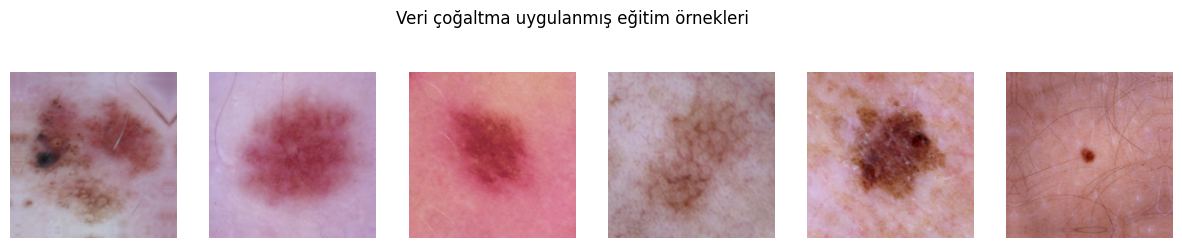

In [ ]:
def oku(yol, y):
    goruntu = tf.io.decode_jpeg(tf.io.read_file(yol), channels=3)
    goruntu = tf.image.resize(goruntu, (IMG, IMG))
    return tf.cast(goruntu, tf.uint8), y   # bellekte az yer kaplasın diye uint8

cogaltma = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.25, fill_mode='reflect'),
    layers.RandomZoom(0.15, fill_mode='reflect'),
    layers.RandomContrast(0.15),
], name='veri_cogaltma')

def veri_hatti(df, egitim_mi):
    ds = tf.data.Dataset.from_tensor_slices((df['path'].values, df['y'].values))
    ds = ds.map(oku, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if egitim_mi:
        ds = ds.shuffle(len(df), seed=TOHUM, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    if egitim_mi:
        ds = ds.map(lambda x, y: (cogaltma(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

egitim_ds    = veri_hatti(egitim, True)
dogrulama_ds = veri_hatti(dogrulama, False)
y_dogrulama  = dogrulama['y'].values

# Çoğaltılmış birkaç eğitim görüntüsüne göz at
ornek, _ = next(iter(egitim_ds))
fig, eksen = plt.subplots(1, 6, figsize=(15, 3))
for i in range(6):
    eksen[i].imshow(np.clip(ornek[i].numpy(), 0, 255).astype('uint8')); eksen[i].axis('off')
plt.suptitle('Veri çoğaltma uygulanmış eğitim örnekleri'); plt.show()

## 4. Sınıf ağırlıkları
Nadir sınıflarda yapılan hatalar daha çok cezalandırılır.
- **dengeli:** ağırlık = toplam / (sınıf sayısı × o sınıfın örnek sayısı). En nadir sınıf, nevüsün ~63 katı ağırlık alır. v1'de bu kullanıldı ve model nadir sınıfları gereğinden fazla tahmin etti.
- **karekok:** dengeli ağırlıkların karekökü. Fark ~8 kata iner; nadir sınıflar yine öne çıkar ama model dengesini kaybetmez.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
agirlik = compute_class_weight('balanced', classes=np.arange(len(SINIFLAR)), y=egitim['y'].values)
if AGIRLIK_TIPI == 'karekok':
    agirlik = np.sqrt(agirlik)
    agirlik = agirlik / (agirlik * np.bincount(egitim['y'], minlength=len(SINIFLAR))).sum() * len(egitim)  # ortalama ağırlık 1 olsun
SINIF_AGIRLIGI = {i: float(a) for i, a in enumerate(agirlik)}
print(pd.DataFrame({'sinif': [SINIF_ADI[s] for s in SINIFLAR],
                    'egitim_ornegi': np.bincount(egitim['y'], minlength=len(SINIFLAR)),
                    'agirlik': agirlik.round(2)}).to_string(index=False))
print(f'En büyük / en küçük ağırlık oranı: {agirlik.max() / agirlik.min():.1f}')

                  sinif  egitim_ornegi  agirlik
        Aktinik keratoz            233     2.60
 Bazal hücreli karsinom            365     2.08
         Benign keratoz            775     1.43
          Dermatofibrom             76     4.56
                Melanom            777     1.43
Melanositik nevüs (ben)           4730     0.58
        Vasküler lezyon             98     4.01
En büyük / en küçük ağırlık oranı: 7.9


## 5. Modeli kur
- **EfficientNet** (B0 veya B3), ImageNet'teki milyonlarca görüntüyle önceden eğitilmiş olarak gelir (transfer öğrenme). Kendi ön işlemesini içerir; 0-255 aralığındaki görüntüyü doğrudan alır.
- Üstüne bir **Dropout** ve **7 sınıflı çıkış katmanı** ekliyoruz.
- Çıkış katmanı olasılık yerine **logit** (ham skor) verir. Adım 3'teki kalibrasyon (sıcaklık ölçekleme) logitlere ihtiyaç duyar; olasılığı softmax ile biz hesaplarız.
- Ara katmanlar düz bir yapıda tutulur; böylece Adım 3'te ısı haritası (Grad-CAM) ve Adım 4'te benzer vaka arşivi için içlerine erişebiliriz.

In [ ]:
girdi = keras.Input(shape=(IMG, IMG, 3), name='goruntu')
GOVDE = {'B0': keras.applications.EfficientNetB0, 'B3': keras.applications.EfficientNetB3}[MODEL_TIPI]
govde = GOVDE(include_top=False, weights=AGIRLIKLAR, input_tensor=girdi)
x = layers.GlobalAveragePooling2D(name='gap')(govde.output)      # Adım 4'te gömme vektörü buradan alınacak
x = layers.Dropout(0.3, name='dropout')(x)
cikti = layers.Dense(len(SINIFLAR), dtype='float32', name='logit')(x)
model = keras.Model(girdi, cikti, name=MODEL_ADI)

GOVDE_KATMANLARI = govde.layers[1:]   # giriş katmanı hariç
for k in GOVDE_KATMANLARI:
    k.trainable = False
print('Toplam katman:', len(model.layers), '| Gövde katmanı:', len(GOVDE_KATMANLARI))
print('Eğitilebilir parametre (1. aşama):', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Toplam katman: 241 | Gövde katmanı: 237
Eğitilebilir parametre (1. aşama): 8967


## 6. En iyi modeli seçen kayıt düzeneği
Her turun sonunda doğrulama kümesinde iki şey hesaplanır:
- **Doğrulama kaybı:** Modelin doğru sınıfa verdiği olasılığın ne kadar yüksek olduğunu ölçer. Bütün sınıfları ve bütün olasılıkları hesaba katar; tur tur daha kararlıdır. **v3'te en iyi tur buna göre seçilir.**
- **Dengeli doğruluk:** Bilgi için yazdırılır. Nadir sınıflarda örnek az olduğu için (ör. 17 dermatofibrom) tek bir görüntü bile sonucu değiştirir; seçim ölçütü olarak gürültülüdür.

En iyi tur Drive'a kaydedilir; ölçüt `SABIR` kadar tur iyileşmezse eğitim durur.

In [ ]:
from sklearn.metrics import balanced_accuracy_score

class EnIyiModelKaydi(keras.callbacks.Callback):
    def __init__(self, ds, y, yol, sabir, olcut='val_loss'):
        super().__init__()
        self.ds, self.y, self.yol, self.sabir, self.olcut = ds, y, yol, sabir, olcut
        self.en_iyi, self.bekleme = None, 0
        self.gecmis, self.kayip_gecmis = [], []          # dengeli doğruluk ve kayıp, tur tur
        self.en_iyi_tur, self.en_iyi_dengeli, self.en_iyi_kayip = None, None, None

    def on_epoch_end(self, epoch, logs=None):
        logit = self.model.predict(self.ds, verbose=0).astype('float64')
        log_olasilik = logit - logit.max(1, keepdims=True)
        log_olasilik -= np.log(np.exp(log_olasilik).sum(1, keepdims=True))
        kayip_degeri = float(-log_olasilik[np.arange(len(self.y)), self.y].mean())
        dengeli = float(balanced_accuracy_score(self.y, logit.argmax(1)))
        self.kayip_gecmis.append(kayip_degeri); self.gecmis.append(dengeli)

        skor = -kayip_degeri if self.olcut == 'val_loss' else dengeli
        if self.en_iyi is None or skor > self.en_iyi:
            self.en_iyi, self.bekleme = skor, 0
            self.en_iyi_tur, self.en_iyi_dengeli, self.en_iyi_kayip = epoch + 1, dengeli, kayip_degeri
            self.model.save(self.yol)
            print(f'  -> kayıp: {kayip_degeri:.4f} | dengeli doğruluk: {dengeli:.4f}  (en iyi, kaydedildi)')
        else:
            self.bekleme += 1
            print(f'  -> kayıp: {kayip_degeri:.4f} | dengeli doğruluk: {dengeli:.4f}  (bekleme {self.bekleme}/{self.sabir})')
            if self.bekleme >= self.sabir:
                self.model.stop_training = True
                print('  Erken durdurma: iyileşme yok.')

MODEL_YOLU = f'{PROJE}/models/{MODEL_ADI}.keras'
kayit = EnIyiModelKaydi(dogrulama_ds, y_dogrulama, MODEL_YOLU, SABIR, SECIM_OLCUTU)
kayip = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

## 7. Aşama 1: Yalnızca sınıflandırma katmanını eğit
Gövde dondurulmuş durumda; yalnızca en üstteki yeni katman öğrenir. Bu, rastgele başlayan katmanın önceden eğitilmiş ağırlıkları bozmasını engeller.

In [ ]:
model.compile(optimizer=keras.optimizers.AdamW(LR_BAS, weight_decay=AGIRLIK_AZALMA), loss=kayip, metrics=['accuracy'])
t0 = time.time()
gecmis1 = model.fit(egitim_ds, validation_data=dogrulama_ds, epochs=EPOCH_BAS,
                    class_weight=SINIF_AGIRLIGI, callbacks=[kayit], verbose=2)
print(f'Aşama 1 süresi: {(time.time() - t0) / 60:.1f} dk')

Epoch 1/5
  -> kayıp: 0.8477 | dengeli doğruluk: 0.3535  (en iyi, kaydedildi)
221/221 - 115s - 522ms/step - accuracy: 0.6490 - loss: 1.4377 - val_accuracy: 0.7240 - val_loss: 0.8477
Epoch 2/5
  -> kayıp: 0.7572 | dengeli doğruluk: 0.4209  (en iyi, kaydedildi)
221/221 - 15s - 70ms/step - accuracy: 0.6823 - loss: 1.2039 - val_accuracy: 0.7480 - val_loss: 0.7572
Epoch 3/5
  -> kayıp: 0.7441 | dengeli doğruluk: 0.4400  (en iyi, kaydedildi)
221/221 - 15s - 69ms/step - accuracy: 0.6985 - loss: 1.1142 - val_accuracy: 0.7404 - val_loss: 0.7441
Epoch 4/5
  -> kayıp: 0.7469 | dengeli doğruluk: 0.4547  (bekleme 1/6)
221/221 - 15s - 66ms/step - accuracy: 0.7031 - loss: 1.0813 - val_accuracy: 0.7391 - val_loss: 0.7469
Epoch 5/5
  -> kayıp: 0.7031 | dengeli doğruluk: 0.4449  (en iyi, kaydedildi)
221/221 - 15s - 69ms/step - accuracy: 0.7176 - loss: 1.0178 - val_accuracy: 0.7548 - val_loss: 0.7031
Aşama 1 süresi: 2.9 dk


## 8. Aşama 2: İnce ayar
Gövdenin katmanları (v2'den beri tamamı) eğitime açılır ve daha küçük bir öğrenme oranıyla eğitilir.
**Batch normalization katmanları dondurulmuş kalır**; aksi halde küçük batch'lerde önceden öğrenilmiş istatistikler bozulur.

In [ ]:
acilacak = GOVDE_KATMANLARI if ACILACAK == 'hepsi' else GOVDE_KATMANLARI[-ACILACAK:]
for k in acilacak:
    if not isinstance(k, layers.BatchNormalization):
        k.trainable = True
print('Eğitilebilir parametre (2. aşama):', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

kayit.bekleme = 0
model.compile(optimizer=keras.optimizers.AdamW(LR_INCE, weight_decay=AGIRLIK_AZALMA), loss=kayip, metrics=['accuracy'])
lr_azalt = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
t0 = time.time()
gecmis2 = model.fit(egitim_ds, validation_data=dogrulama_ds, epochs=EPOCH_BAS + EPOCH_INCE,
                    initial_epoch=len(gecmis1.history['loss']),
                    class_weight=SINIF_AGIRLIGI, callbacks=[kayit, lr_azalt], verbose=2)
print(f'Aşama 2 süresi: {(time.time() - t0) / 60:.1f} dk')
print(f'En iyi tur: {kayit.en_iyi_tur} | kayıp: {kayit.en_iyi_kayip:.4f} | dengeli doğruluk: {kayit.en_iyi_dengeli:.4f}  ->  {MODEL_YOLU}')

Eğitilebilir parametre (2. aşama): 3974499
Epoch 6/35
  -> kayıp: 0.5431 | dengeli doğruluk: 0.5958  (en iyi, kaydedildi)
221/221 - 259s - 1s/step - accuracy: 0.7295 - loss: 0.9094 - val_accuracy: 0.7978 - val_loss: 0.5431 - learning_rate: 1.0000e-04
Epoch 7/35
  -> kayıp: 0.5939 | dengeli doğruluk: 0.6997  (bekleme 1/6)
221/221 - 15s - 69ms/step - accuracy: 0.7810 - loss: 0.7060 - val_accuracy: 0.7787 - val_loss: 0.5939 - learning_rate: 1.0000e-04
Epoch 8/35
  -> kayıp: 0.6765 | dengeli doğruluk: 0.5819  (bekleme 2/6)
221/221 - 15s - 68ms/step - accuracy: 0.8075 - loss: 0.6187 - val_accuracy: 0.7602 - val_loss: 0.6765 - learning_rate: 1.0000e-04
Epoch 9/35
  -> kayıp: 0.5049 | dengeli doğruluk: 0.5978  (en iyi, kaydedildi)
221/221 - 16s - 74ms/step - accuracy: 0.8270 - loss: 0.5287 - val_accuracy: 0.8190 - val_loss: 0.5049 - learning_rate: 1.0000e-04
Epoch 10/35
  -> kayıp: 0.4602 | dengeli doğruluk: 0.6953  (en iyi, kaydedildi)
221/221 - 16s - 74ms/step - accuracy: 0.8384 - loss: 0.4

## 9. Eğitim eğrileri

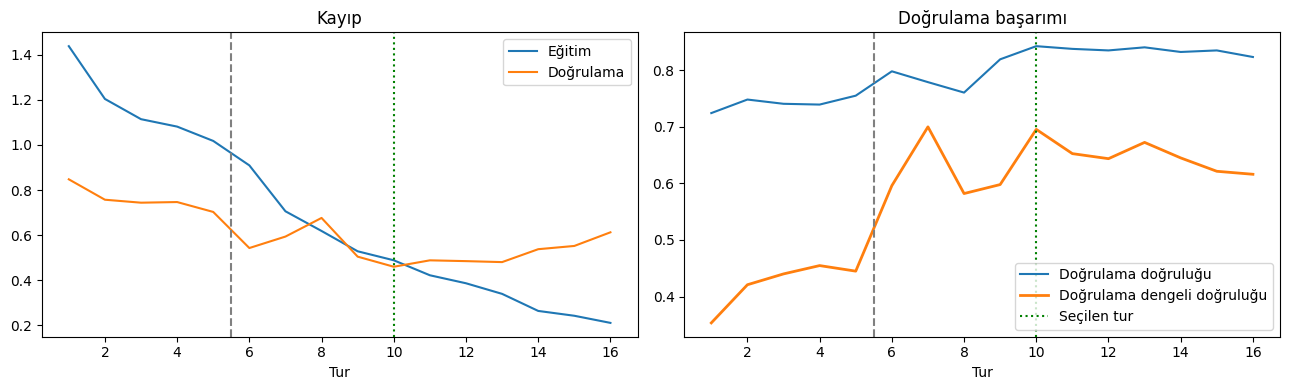

In [ ]:
h = {k: gecmis1.history[k] + gecmis2.history.get(k, []) for k in gecmis1.history}
turlar = np.arange(1, len(h['loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(turlar, h['loss'], label='Eğitim'); ax[0].plot(turlar, h['val_loss'], label='Doğrulama')
ax[0].set_title('Kayıp'); ax[0].set_xlabel('Tur'); ax[0].legend()
ax[1].plot(turlar, h['val_accuracy'], label='Doğrulama doğruluğu')
ax[1].plot(turlar, kayit.gecmis, label='Doğrulama dengeli doğruluğu', linewidth=2)
ax[1].set_title('Doğrulama başarımı'); ax[1].set_xlabel('Tur'); ax[1].legend()
for a in ax: a.axvline(EPOCH_BAS + 0.5, color='gray', linestyle='--')
for a in ax: a.axvline(kayit.en_iyi_tur, color='green', linestyle=':', label='Seçilen tur')
ax[1].legend()
plt.tight_layout(); plt.savefig(f'{PROJE}/results/02_{MODEL_ADI}_egitim_egrisi.png', dpi=150); plt.show()
pd.DataFrame({**h, 'val_bal_acc': kayit.gecmis}).to_csv(f'{PROJE}/results/02_{MODEL_ADI}_egitim_gecmisi.csv', index_label='tur')

## 10. En iyi modeli doğrulama kümesinde değerlendir
Kaydedilen **en iyi** model yüklenir. Test kümesine hâlâ dokunmuyoruz; o, Adım 3'te kalibrasyondan sonra yalnızca bir kez kullanılacak.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score

en_iyi_model = keras.models.load_model(MODEL_YOLU)
logit_dog = en_iyi_model.predict(dogrulama_ds, verbose=0)
olasilik_dog = tf.nn.softmax(logit_dog).numpy()
tahmin_dog = olasilik_dog.argmax(1)

metrikler = {
    'dengeli_dogruluk': float(balanced_accuracy_score(y_dogrulama, tahmin_dog)),
    'dogruluk': float((tahmin_dog == y_dogrulama).mean()),
    'makro_f1': float(f1_score(y_dogrulama, tahmin_dog, average='macro')),
    'makro_auc': float(roc_auc_score(y_dogrulama, olasilik_dog, multi_class='ovr', average='macro')),
}
rapor = classification_report(y_dogrulama, tahmin_dog, labels=range(len(SINIFLAR)),
                              target_names=[SINIF_ADI[s] for s in SINIFLAR], digits=3,
                              output_dict=True, zero_division=0)
metrikler['melanom_duyarliligi'] = float(rapor['Melanom']['recall'])

print('DOĞRULAMA SONUÇLARI')
for k, v in metrikler.items():
    print(f'  {k:22s}: {v:.4f}')
print()
print(classification_report(y_dogrulama, tahmin_dog, labels=range(len(SINIFLAR)),
                            target_names=[SINIF_ADI[s] for s in SINIFLAR], digits=3, zero_division=0))

DOĞRULAMA SONUÇLARI
  dengeli_dogruluk      : 0.6953
  dogruluk              : 0.8422
  makro_f1              : 0.7132
  makro_auc             : 0.9678
  melanom_duyarliligi   : 0.5298

                         precision    recall  f1-score   support

        Aktinik keratoz      0.793     0.535     0.639        43
 Bazal hücreli karsinom      0.667     0.722     0.693        72
         Benign keratoz      0.619     0.838     0.712       167
          Dermatofibrom      0.625     0.588     0.606        17
                Melanom      0.664     0.530     0.589       168
Melanositik nevüs (ben)      0.937     0.926     0.931       975
        Vasküler lezyon      0.941     0.727     0.821        22

               accuracy                          0.842      1464
              macro avg      0.749     0.695     0.713      1464
           weighted avg      0.848     0.842     0.841      1464



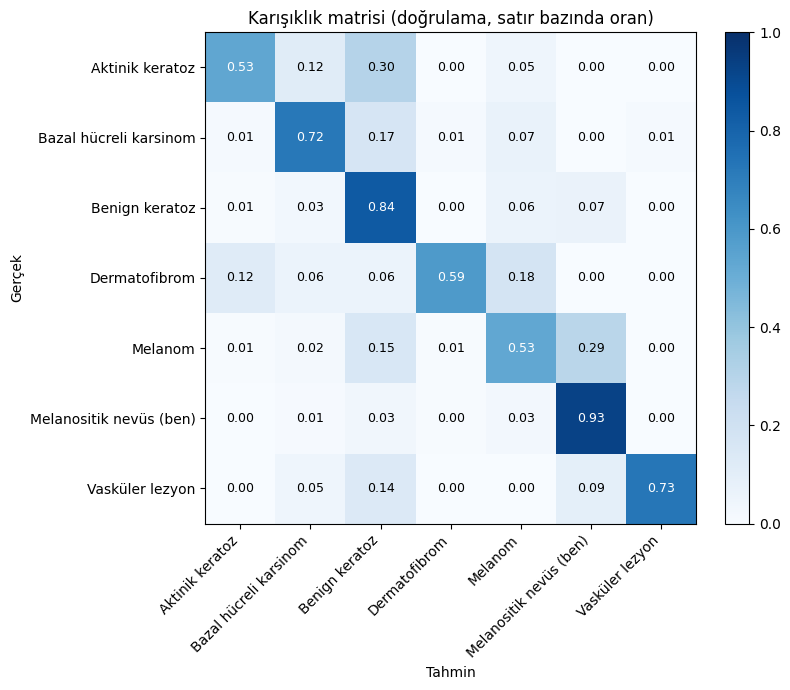

In [ ]:
km = confusion_matrix(y_dogrulama, tahmin_dog, labels=range(len(SINIFLAR)), normalize='true')
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(km, cmap='Blues', vmin=0, vmax=1)
etiket = [SINIF_ADI[s] for s in SINIFLAR]
ax.set_xticks(range(len(etiket)), etiket, rotation=45, ha='right'); ax.set_yticks(range(len(etiket)), etiket)
for i in range(len(etiket)):
    for j in range(len(etiket)):
        ax.text(j, i, f'{km[i, j]:.2f}', ha='center', va='center', color='white' if km[i, j] > 0.5 else 'black', fontsize=9)
ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek'); ax.set_title('Karışıklık matrisi (doğrulama, satır bazında oran)')
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(f'{PROJE}/results/02_{MODEL_ADI}_karisiklik_matrisi.png', dpi=150); plt.show()

## 10b. Karar ayarı (logit ayarı)
Eğitim verisinin %67'si ben olduğu için model, emin olmadığı durumda "ben" demeye eğilimlidir. Bu, en tehlikeli hatayı (melanoma "ben" demek) artırır.

**Logit ayarı** bu eğilimi eğitimden sonra düzeltir:

  ayarlı skor = logit − τ × log(o sınıfın eğitimdeki oranı)

- τ = 0: hiçbir değişiklik yok.
- τ büyüdükçe sık görülen sınıfların (ben) avantajı azalır, nadir sınıflar öne çıkar.
- Tek bir sayı (τ) doğrulama kümesinde, dengeli doğruluğu en yüksek yapacak şekilde seçilir. Model yeniden eğitilmez.

**Dikkat:** τ doğrulama kümesinde seçildiği için aşağıdaki "ayarlı" sonuç biraz iyimserdir. Gerçek ölçüm, Adım 3'te test kümesinde yapılacak.

Seçilen τ = 1.05

              olcut  ayarsiz  ayarli
   Dengeli doğruluk    0.695   0.740
           Doğruluk    0.842   0.699
           Makro F1    0.713   0.600
Melanom duyarlılığı    0.530   0.714

Sınıf bazında duyarlılık (ayarsız -> ayarlı):
  Aktinik keratoz           0.535 -> 0.558
  Bazal hücreli karsinom    0.722 -> 0.708
  Benign keratoz            0.838 -> 0.772
  Dermatofibrom             0.588 -> 0.882
  Melanom                   0.530 -> 0.714
  Melanositik nevüs (ben)   0.926 -> 0.682
  Vasküler lezyon           0.727 -> 0.864


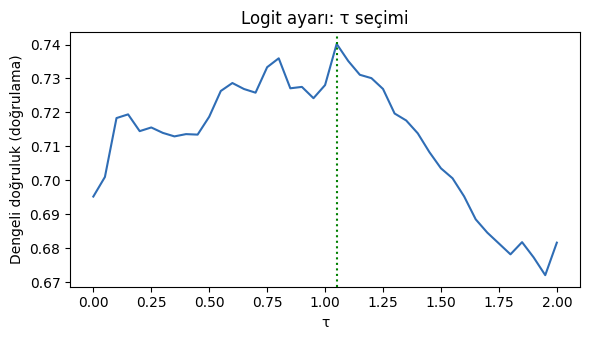

In [ ]:
oncel = np.bincount(egitim['y'], minlength=len(SINIFLAR)) / len(egitim)
log_oncel = np.log(oncel)
taular = np.round(np.arange(0, 2.0001, 0.05), 2)
dengeli_tau = [balanced_accuracy_score(y_dogrulama, (logit_dog - t * log_oncel).argmax(1)) for t in taular]
TAU = float(taular[int(np.argmax(dengeli_tau))])

tahmin_ayarli = (logit_dog - TAU * log_oncel).argmax(1)
rapor_ayarli = classification_report(y_dogrulama, tahmin_ayarli, labels=range(len(SINIFLAR)),
                                     target_names=[SINIF_ADI[s] for s in SINIFLAR], digits=3,
                                     output_dict=True, zero_division=0)
metrikler['tau'] = TAU
metrikler['ayarli_dengeli_dogruluk'] = float(balanced_accuracy_score(y_dogrulama, tahmin_ayarli))
metrikler['ayarli_dogruluk'] = float((tahmin_ayarli == y_dogrulama).mean())
metrikler['ayarli_makro_f1'] = float(f1_score(y_dogrulama, tahmin_ayarli, average='macro'))
metrikler['ayarli_melanom_duyarliligi'] = float(rapor_ayarli['Melanom']['recall'])

print(f'Seçilen τ = {TAU}\n')
print(pd.DataFrame({
    'olcut': ['Dengeli doğruluk', 'Doğruluk', 'Makro F1', 'Melanom duyarlılığı'],
    'ayarsiz': [metrikler['dengeli_dogruluk'], metrikler['dogruluk'], metrikler['makro_f1'], metrikler['melanom_duyarliligi']],
    'ayarli': [metrikler['ayarli_dengeli_dogruluk'], metrikler['ayarli_dogruluk'], metrikler['ayarli_makro_f1'], metrikler['ayarli_melanom_duyarliligi']],
}).round(3).to_string(index=False))
print('\nSınıf bazında duyarlılık (ayarsız -> ayarlı):')
for s in SINIFLAR:
    a = SINIF_ADI[s]
    print(f'  {a:25s} {rapor[a]["recall"]:.3f} -> {rapor_ayarli[a]["recall"]:.3f}')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(taular, dengeli_tau, color='#2F6DB5'); ax.axvline(TAU, color='green', linestyle=':')
ax.set_xlabel('τ'); ax.set_ylabel('Dengeli doğruluk (doğrulama)'); ax.set_title('Logit ayarı: τ seçimi')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/02_{MODEL_ADI}_logit_ayari.png', dpi=150); plt.show()

## 11. Sonuçları kaydet
Doğrulama logitleri Adım 3'teki kalibrasyon için gerekli.

In [ ]:
np.save(f'{PROJE}/models/{MODEL_ADI}_dogrulama_logit.npy', logit_dog)
np.save(f'{PROJE}/models/{MODEL_ADI}_dogrulama_y.npy', y_dogrulama)
pd.DataFrame(rapor).T.to_csv(f'{PROJE}/results/02_{MODEL_ADI}_siniflandirma_raporu.csv')
with open(f'{PROJE}/results/02_{MODEL_ADI}_dogrulama_metrikleri.json', 'w', encoding='utf-8') as f:
    json.dump({'model': MODEL_ADI, 'img': IMG, 'siniflar': SINIFLAR, **metrikler,
               'ayarlar': {'model_tipi': MODEL_TIPI, 'agirlik_tipi': AGIRLIK_TIPI, 'secim_olcutu': SECIM_OLCUTU,
                           'agirlik_azalma': AGIRLIK_AZALMA, 'secilen_tur': kayit.en_iyi_tur, 'batch': BATCH, 'epoch_bas': EPOCH_BAS, 'epoch_ince': EPOCH_INCE,
                           'lr_bas': LR_BAS, 'lr_ince': LR_INCE, 'acilan_katman': ACILACAK,
                           'tur_sayisi': len(kayit.gecmis)}},
              f, ensure_ascii=False, indent=2)
print('Kaydedildi:')
for p in [f'models/{MODEL_ADI}.keras', f'models/{MODEL_ADI}_dogrulama_logit.npy',
          f'results/02_{MODEL_ADI}_egitim_egrisi.png', f'results/02_{MODEL_ADI}_karisiklik_matrisi.png',
          f'results/02_{MODEL_ADI}_siniflandirma_raporu.csv', f'results/02_{MODEL_ADI}_dogrulama_metrikleri.json',
          f'results/02_{MODEL_ADI}_egitim_gecmisi.csv', f'results/02_{MODEL_ADI}_logit_ayari.png']:
    print(' ', p, '✓' if os.path.exists(f'{PROJE}/{p}') else 'YOK!')

Kaydedildi:
  models/cnn_b0_v3.keras ✓
  models/cnn_b0_v3_dogrulama_logit.npy ✓
  results/02_cnn_b0_v3_egitim_egrisi.png ✓
  results/02_cnn_b0_v3_karisiklik_matrisi.png ✓
  results/02_cnn_b0_v3_siniflandirma_raporu.csv ✓
  results/02_cnn_b0_v3_dogrulama_metrikleri.json ✓
  results/02_cnn_b0_v3_egitim_gecmisi.csv ✓
  results/02_cnn_b0_v3_logit_ayari.png ✓


## 12. Önceki denemelerle karşılaştır
Drive'daki bütün Adım 2 sonuçlarını tek tabloda gösterir (v1 sonucu `02_dogrulama_metrikleri.json` adıyla kayıtlı).

In [ ]:
satirlar = []
for yol in sorted(glob.glob(f'{PROJE}/results/02*dogrulama_metrikleri.json')):
    with open(yol, encoding='utf-8') as f:
        m = json.load(f)
    satirlar.append({'model': m['model'] + (' (v1)' if os.path.basename(yol) == '02_dogrulama_metrikleri.json' else ''),
                     'dengeli_dogruluk': m['dengeli_dogruluk'], 'dogruluk': m['dogruluk'],
                     'makro_f1': m['makro_f1'], 'makro_auc': m['makro_auc'],
                     'melanom_duyarliligi': m['melanom_duyarliligi'],
                     'ayarli_dengeli': m.get('ayarli_dengeli_dogruluk'),
                     'ayarli_melanom': m.get('ayarli_melanom_duyarliligi')})
print(pd.DataFrame(satirlar).round(3).to_string(index=False))
print('\n"ayarli" sütunları yalnızca v3 ve sonrasında var (logit ayarı uygulanmış, doğrulamada seçilmiş τ ile).')

      model  dengeli_dogruluk  dogruluk  makro_f1  makro_auc  melanom_duyarliligi  ayarli_dengeli  ayarli_melanom
  cnn_b0_v2             0.673     0.766     0.602      0.952                0.446             NaN             NaN
  cnn_b0_v3             0.695     0.842     0.713      0.968                0.530            0.74           0.714
cnn_b0 (v1)             0.653     0.642     0.487      0.929                0.583             NaN             NaN

"ayarli" sütunları yalnızca v3 ve sonrasında var (logit ayarı uygulanmış, doğrulamada seçilmiş τ ile).


## Bu adımın sonunda
- En iyi model Drive'da: `bitirme/models/cnn_b0_v3.keras`
- **Bana gönder:** defteri *Dosya → İndir → .ipynb* ile indirip gönder. Karşılaştırma tablosuna bakıp CNN'i yeterli sayıp sayamayacağımıza karar vereceğiz.